Since Stanza Turkish stopwords package is not sufficiently developed, I will use text_lemma to capture meaningless collocations and debug in text_phrases.

Both theory-driven and also updates stanza's mistakes.

In [9]:
# ── INITIALIZE ──────────────────────────
import importlib, preprocessing_pipeline_copy
importlib.reload(preprocessing_pipeline_copy)
from preprocessing_pipeline_copy import PreprocessingPipeline

pipeline = PreprocessingPipeline("/Users/erenisikavci/Desktop/Thesis_Data/Data/corpus_main.csv")
pipeline.load_lemma_csv()

# update 
pipeline.build_text_phrases()

# initialize df
df = pipeline.df
print(f"df ready: {len(df)} obs, {list(df.columns)} cols")

Corpus loaded: 2744 rows
Loaded: /Users/erenisikavci/Desktop/Thesis_Data/Data/corpus_main_lemma.csv (2726 rows)
Saved: /Users/erenisikavci/Desktop/Thesis_Data/Data/corpus_main_phrases.csv
df ready: 2726 obs, ['id', 'text', 'date', 'title', 'url', 'venue', 'speaker', 'format', 'text_length', 'year', 'month', 'quarter', 'text_raw', 'text_lemma', 'text_phrases'] cols


## TEXT_LEMMA

In [56]:
# raw frequency
pipeline.show_freq(col='text_lemma', n=300)


-- TEXT_LEMMA FREQUENCY (top 300) --
parti                                    40696
türkiye                                  38709
başkan                                   34335
ülke                                     21642
devlet                                   21213
belediye                                 17135
arkadaş                                  17125
sorun                                    16527
genel                                    16469
para                                     15027
seçim                                    14947
cumhuriyet                               14694
insan                                    14686
lazım                                    14488
kişi                                     14266
büyük                                    13407
halk                                     13363
lira                                     12184
millet                                   11636
iktidar                                  11606
dünya                 

In [27]:
# discover theoretically meaningful candidate collocations from text_lemma 
# add that collocation to text_phrases 
pipeline.show_collocations(col="text_phrases", n=400, min_count = 5, threshold=0.5)


-- COLLOCATIONS (top 400) --
  değerli_arkadaş: 3517
  belediye_başkan: 3193
  genel_başkan: 1705
  ekrem_imamoğlu: 1391
  siyasi_parti: 1249
  asgari_ücret: 1098
  sahip_çık: 980
  türkiye_devlet: 904
  parti_genel_başkan: 832
  dış_politika: 812
  chp_genel_başkan_kılıçdaroğlu: 794
  chp_belediye: 790
  anayasa_mahkeme: 756
  türkiye_büyük_millet_tbmm: 714
  chp_genel_başkan: 686
  açık_net: 655
  özgür_özel: 652
  terör_örgüt: 639
  ifade_edeyim: 636
  orta_çık: 625
  genel_başkan_kılıçdaroğlu: 622
  covid_pandemi: 616
  devlet_bahçeli: 614
  son_derece: 600
  insan_hak: 589
  anayasa_değişiklik: 573
  yerel_seçim: 571
  chp_iktidar: 558
  geç_sene: 532
  parti_parti: 524
  sosyal_devlet: 497
  başka_yer: 488
  son_yıl: 485
  adam_rejim: 477
  bay_kemal: 473
  ekrem_bey: 471
  sorun_çöz: 468
  devlet_yöneten: 467
  siyaset_kurum: 464
  ifade_kullandı: 464
  anne_baba: 461
  chp_genel_başkan_özgür_özel: 461
  hak_hak: 459
  türkiye_demokrasi: 453
  ülke_demokrasi: 453
  darbe_girişi

In [57]:
# inspect different aggluginative forms of chosen collocation for MANUAL_STEM
sample = " ".join(df["text_phrases"].dropna())
tokens = sample.split()
print([t for t in set(tokens) if t.startswith("aile")])

['ailelik', 'ailecek', 'ailele', 'ailenizi', 'ailelerdir', 'aileyi', 'aileme', 'ailesiyiz', 'ailemi', 'ailenizdenim', 'ailesi', 'ailesin', 'ailece', 'aileniz', 'ailesiz', 'ailedir', 'ailevi', 'ailem', 'ailelere', 'ailemdir', 'aileyiz', 'ailemin', 'ailenizin', 'ailelen', 'aileni', 'aileyse', 'aile', 'ailen', 'ailemiz', 'ailene']


In [28]:
# examples from sentences

for _, row in df.iterrows():
    if "allah" in row["text_phrases"]:
        tokens = row["text_phrases"].split()
        for i, t in enumerate(tokens):
            if t == "allah":
                print(tokens[max(0,i-1):i+4])
                break

['çalış', 'allah', 'akıl', 'fikir', 'versin']
['bun', 'allah', 'inancı', 'ahlak', 'demokrasi']
['geçmedi', 'allah', 'akıl', 'miydi', 'efendi']
['söz', 'allah', 'nasip', 'cumhurbaşkanı', 'seçildik']
['çıksın', 'allah', 'rahmet', 'eyle', 'baykal']
['chp', 'allah', 'chp', 'ekonomi', 'soru']
['parti', 'allah', 'kavga', 'türlü', 'komisyon']
['müsünüz', 'allah', 'vicdan', 'kabul', 'evet']
['kaza', 'allah', 'ora', 'ufak', 'tefek']
['severim', 'allah', 'gani', 'gani', 'rahmet']
['kazanacak', 'allah', 'göstermesin', 'kaybederse', 'helikopter']
['kayıp', 'allah', 'umut', 'kesilmez', 'mucize']
['gittik', 'allah', 'kavuştursun', 'döndük', 'göz']
['yapmat', 'allah', 'kul', 'sokak', 'buluyor']
['sokmak', 'allah', 'bağışla', 'aday', 'çıkar']
['tutarsızlık', 'allah', 'allah', 'gerçekten', 'amaç']
['mülk', 'allah', 'ındır', 'mülkü', 'edinmiş']
['mülk', 'allah', 'ındır', 'gör', 'gör']
['başkanım', 'allah', 'razı', 'kazandık', 'ara']
['dışarı', 'allah', 'herhalde', 'yapmat', 'ülke']
['ayrımcılık', 'allah

## TEXT_PHRASES 

In [6]:
# relative frequency of chosen words and collocations over time (in year)

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('/Users/erenisikavci/Desktop/Thesis_Data/Data/corpus_main_phrases.csv')
# assumes columns: text_lemma (str), date (datetime), speaker

df["year"] = pd.to_datetime(df["date"], dayfirst = True).dt.year

def word_freq_per_year(df, words):
    """"""
    yearly_docs = df.groupby("year")["text_phrases"].apply(lambda x: " ".join(x))
    
    rows = []
    for year, doc in yearly_docs.items():

        # show relative frequency normalized by annual token count per each year
        tokens = doc.split()
        total = len(tokens)
        for word in words:
            count = tokens.count(word)
            rows.append({
                "word": word,
                "year": year,
                "rel_freq": count / total if total > 0 else 0
            })
    
    result = pd.DataFrame(rows)
    return result.groupby(["word", "year"])["rel_freq"].sum().unstack("year")

In [58]:
# inspect given string's frequency and count per year

phrase = "ben"

matches = df["text_phrases"].apply(lambda x: phrase in x.split())
print(f"{phrase} in {matches.sum()} speeches")

# relative frequency
pivot = word_freq_per_year(df, [phrase])
print(pivot)

# raw count per year
yearly_docs = df.groupby("year")["text_phrases"].apply(lambda x: " ".join(x))
print("\nraw count per year:")
for year, doc in yearly_docs.items():
    count = doc.split().count(phrase)
    print(f"{year}: {count}")

ben in 2418 speeches
year     2015      2016      2017      2018      2019      2020      2021  \
word                                                                        
ben   0.01464  0.014775  0.017946  0.012137  0.014078  0.013648  0.012831   

year      2022      2023      2024      2025      2026  
word                                                    
ben   0.013101  0.014735  0.010737  0.009851  0.009368  

raw count per year:
2015: 828
2016: 2851
2017: 5525
2018: 2789
2019: 3715
2020: 2670
2021: 3647
2022: 3522
2023: 4182
2024: 7210
2025: 6809
2026: 1857


In [46]:
# kwic

result = pipeline.kwic("alkışlıyoruz", pipeline.df["text"], dates=pipeline.df["month"])
print(result.head(50))


                                                 left  \
0                      ki ben Erdoğan’a çağrı yaptım,   
1   Erdoğan’a çağrı yaptım, "alkışlıyoruz doktorları,   
2           yürekten teşekkür ediyoruz, onları tekrar   
3           şükranlarımızı sunuyoruz ve onları tekrar   
4              bakın hep beraber sağlık çalışanlarını   
5                         olunca da hep beraber zaten   
6        görüyoruz. Alkışlıyor muyuz, yeri geldiğinde   
7            bu mücadelesini yürekten sahipleniyor ve   
8           Hepinizi çok seviyoruz, hepinizi yürekten   
9                  bu arkadaşlar var, onları yürekten   
10               duyayım, en kuvvetli alkış. Gençleri   
11      eğdirmeyen üç kahramanımdır. Hepsini yürekten   
12        sabahının Nizip Belediye Başkanını kuvvetli   
13           Ömürlerini vermişler bu orduya. Yürekten   
14  veren herkesi, belediyemizin emekçilerini yüre...   
15          gelecek, memlekete sahip çıkacak gençleri   
16  çıkacak gençleri alkışlıyor

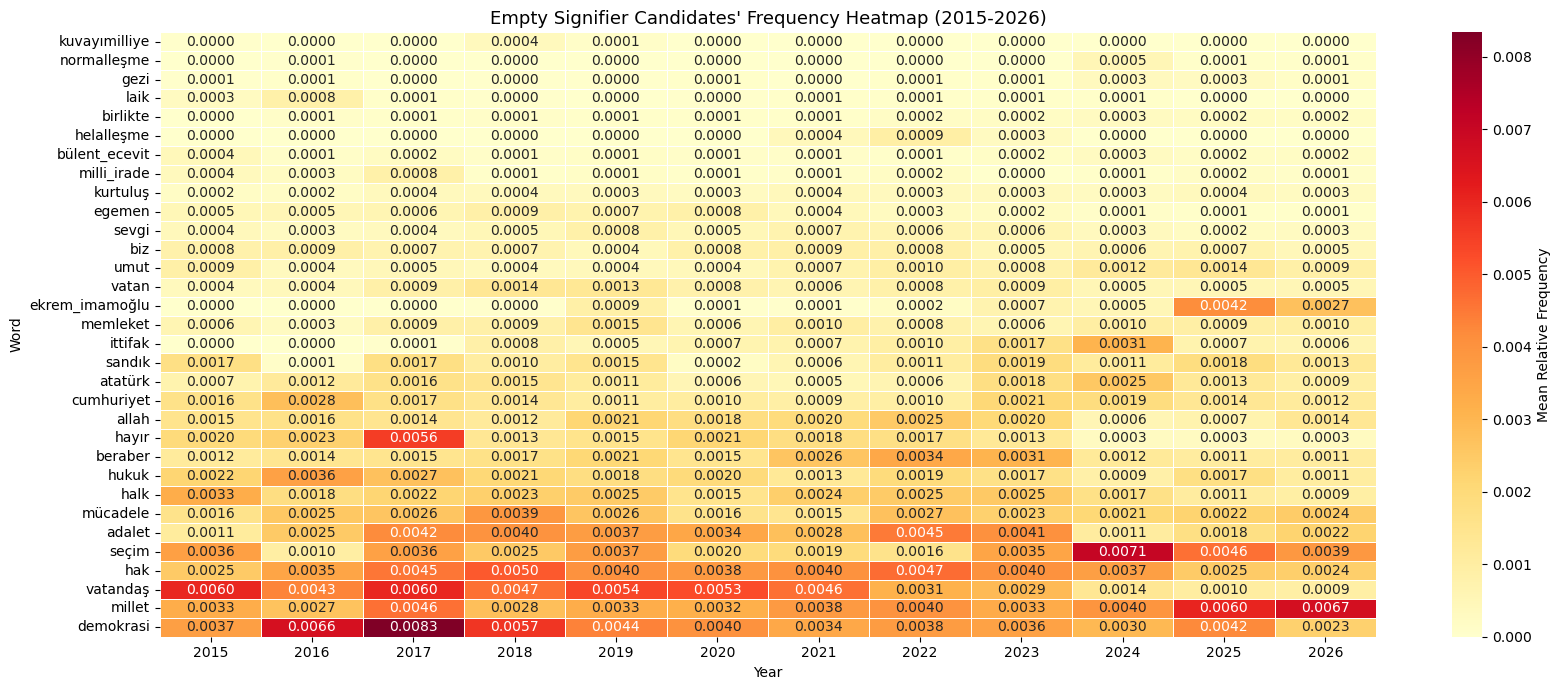

In [40]:
# theory-driven EMPTY_SIGNIFIER candidates
EMPTY_SIGNIFIER = ["halk", "millet", "demokrasi", "adalet", "atatürk", "milli_irade", "egemen", "kuvayımilliye", "cumhuriyet", "hukuk",
                    "hak", "birlikte", "beraber", "allah", "sandık", "memleket", "vatan", "helalleşme", "normalleşme", "gezi", "ittifak", "umut", "laik",
                    "sevgi", "ekrem_imamoğlu", "biz", "kurtuluş", "bülent_ecevit", "vatandaş", "seçim", "hayır", "mücadele"]

pivot = word_freq_per_year(df, EMPTY_SIGNIFIER)
pivot_sorted = pivot.loc[pivot.mean(axis=1).sort_values(ascending=True).index]

fig, ax = plt.subplots(figsize=(17, 7))

sns.heatmap(
    pivot_sorted,
    ax=ax,
    cmap="YlOrRd",        # light = rare, dark = frequent
    linewidths=0.4,
    annot=True,            # shows values in cells -- turn off if too crowded
    fmt=".4f",
    cbar_kws={"label": "Mean Relative Frequency"}
)

ax.set_title("Empty Signifier Candidates' Frequency Heatmap (2015-2026)", fontsize=13)
ax.set_xlabel("Year")
ax.set_ylabel("Word")

plt.tight_layout()
plt.savefig("popular_heatmap.png", dpi=300)
plt.show()

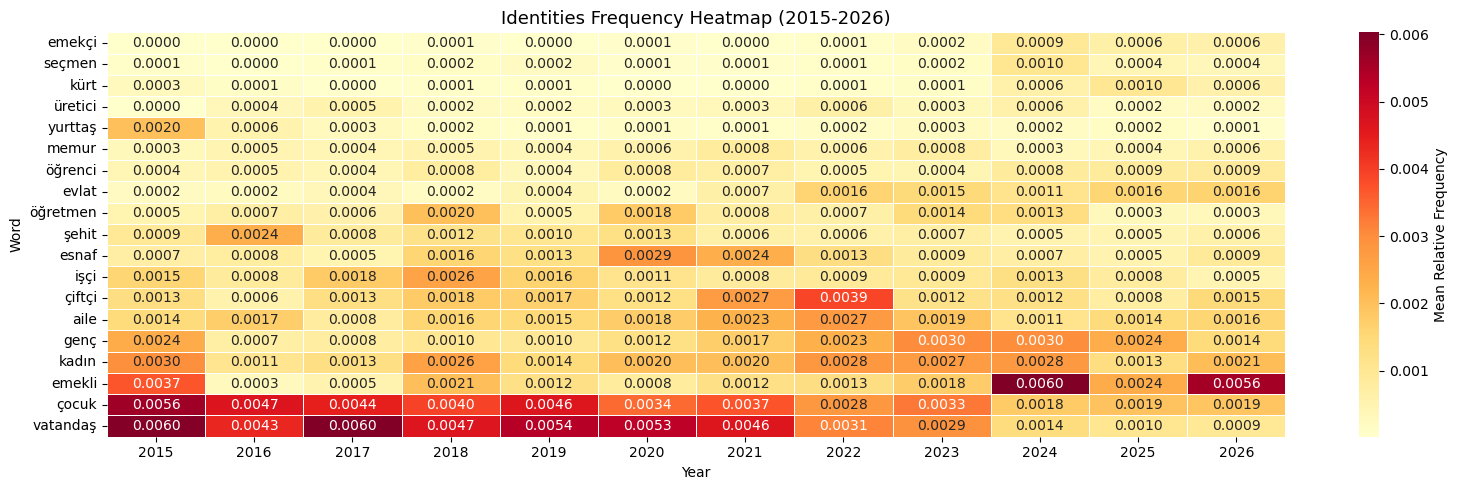

In [41]:
# theory-driven IDENTITIES candidates
IDENTITIES = ["emekli", "işçi", "öğrenci", "aile", "emekçi", "genç", "öğretmen", "çiftçi", "esnaf", "seçmen", "kadın", "kürt", 
                "evlat", "şehit", "üretici", "vatandaş", "çocuk", "memur", "yurttaş"]

pivot = word_freq_per_year(df, IDENTITIES)
pivot_sorted = pivot.loc[pivot.mean(axis=1).sort_values(ascending=True).index]

fig, ax = plt.subplots(figsize=(16, 5))

sns.heatmap(
    pivot_sorted,
    ax=ax,
    cmap="YlOrRd",        # light = rare, dark = frequent
    linewidths=0.4,
    annot=True,            # shows values in cells -- turn off if too crowded
    fmt=".4f",
    cbar_kws={"label": "Mean Relative Frequency"}
)

ax.set_title("Identities Frequency Heatmap (2015-2026)", fontsize=13)
ax.set_xlabel("Year")
ax.set_ylabel("Word")

plt.tight_layout()
plt.savefig("identity_heatmap.png", dpi=300)
plt.show()

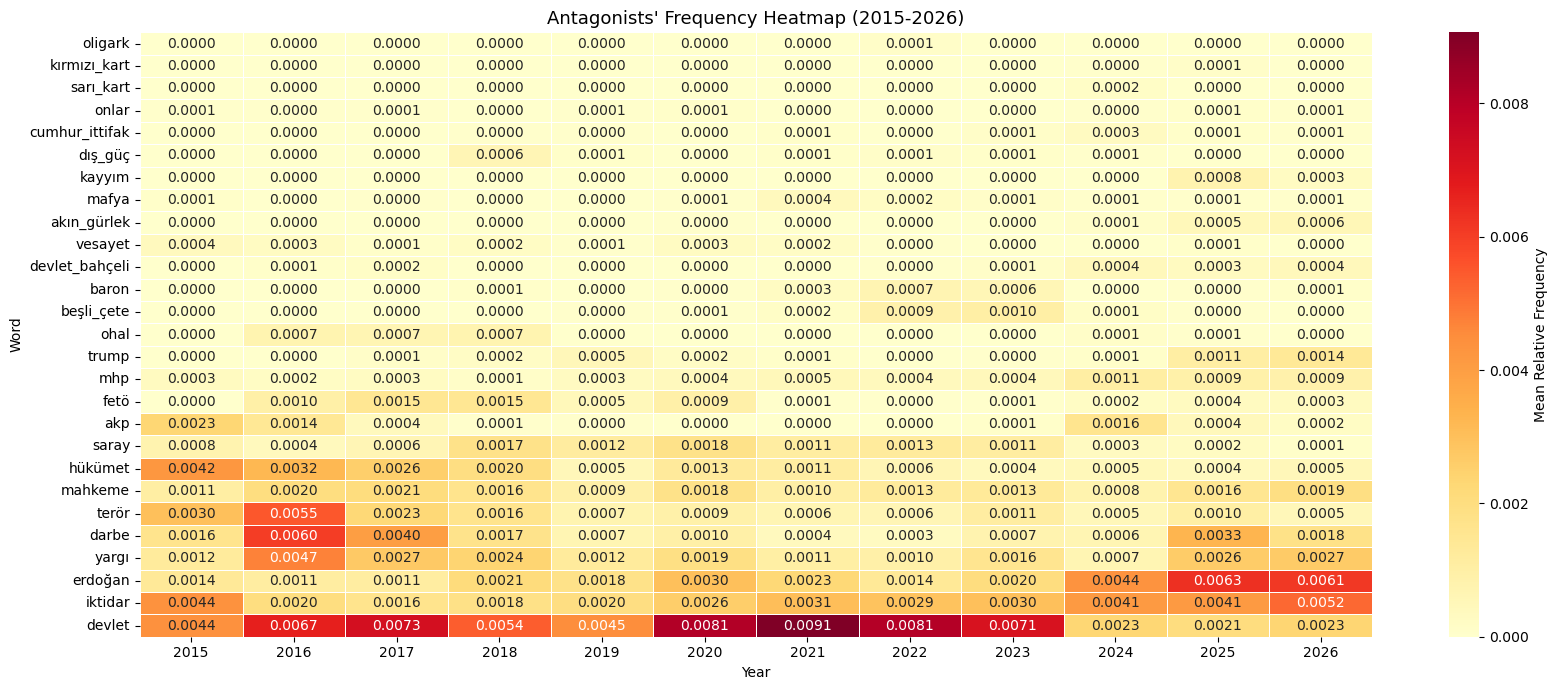

In [42]:
# theory-driven ANTAGONIST candidates
ANTAGONIST = ["iktidar", "erdoğan", "akın_gürlek", "darbe", "terör", "saray", "yargı", "beşli_çete", "mahkeme", "akp", "devlet",
             "hükümet", "mhp", "trump", "fetö", "ohal", "kayyım", "sarı_kart", "kırmızı_kart", "cumhur_ittifak",
             "vesayet", "mafya", "baron", "dış_güç", "devlet_bahçeli", "onlar", "oligark"]

pivot = word_freq_per_year(df, ANTAGONIST)
pivot_sorted = pivot.loc[pivot.mean(axis=1).sort_values(ascending=True).index]

fig, ax = plt.subplots(figsize=(17, 7))

sns.heatmap(
    pivot_sorted,
    ax=ax,
    cmap="YlOrRd",        # light = rare, dark = frequent
    linewidths=0.4,
    annot=True,            # shows values in cells -- turn off if too crowded
    fmt=".4f",
    cbar_kws={"label": "Mean Relative Frequency"}
)

ax.set_title("Antagonists' Frequency Heatmap (2015-2026)", fontsize=13)
ax.set_xlabel("Year")
ax.set_ylabel("Word")

plt.tight_layout()
plt.savefig("antagonist_heatmap.png", dpi=300)
plt.show()

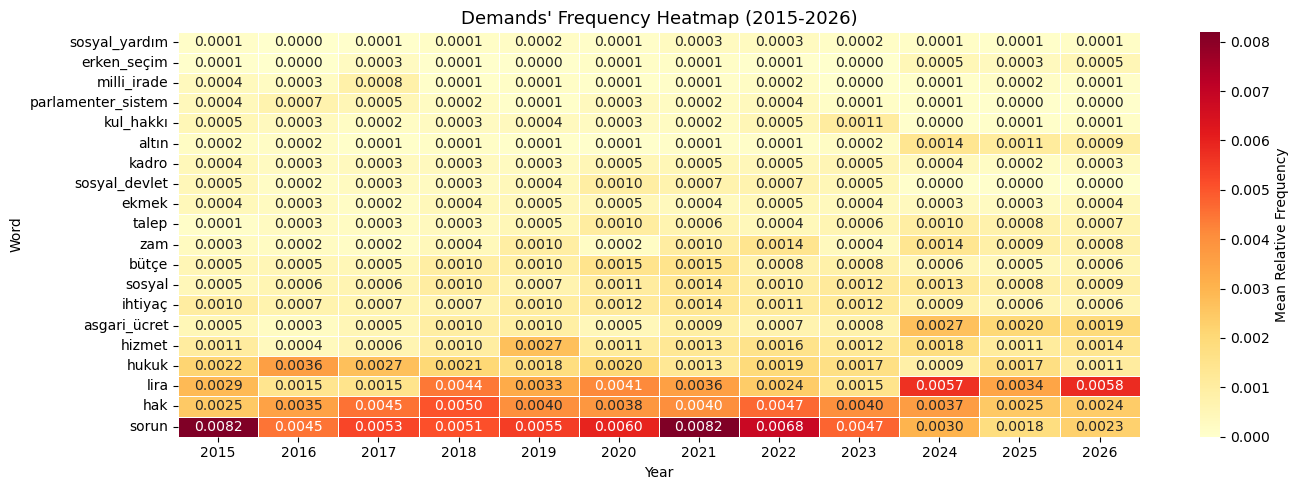

In [43]:
# theory-driven DEMANDS candidates
DEMANDS = ["lira", "asgari_ücret", "ihtiyaç", "talep", "ekmek", "bütçe", "sorun", "zam", "hizmet", "sosyal", "kadro",
            "sosyal_devlet", "parlamenter_sistem", "milli_irade", "hukuk", "hak", "erken_seçim", "sosyal_yardım", "altın",
            "kul_hakkı"]

pivot = word_freq_per_year(df, DEMANDS)
pivot_sorted = pivot.loc[pivot.mean(axis=1).sort_values(ascending=True).index]

fig, ax = plt.subplots(figsize=(14, 5))

sns.heatmap(
    pivot_sorted,
    ax=ax,
    cmap="YlOrRd",        # light = rare, dark = frequent
    linewidths=0.4,
    annot=True,            # shows values in cells -- turn off if too crowded
    fmt=".4f",
    cbar_kws={"label": "Mean Relative Frequency"}
)

ax.set_title("Demands' Frequency Heatmap (2015-2026)", fontsize=13)
ax.set_xlabel("Year")
ax.set_ylabel("Word")

plt.tight_layout()
plt.savefig("demands_heatmap.png", dpi=300)
plt.show()

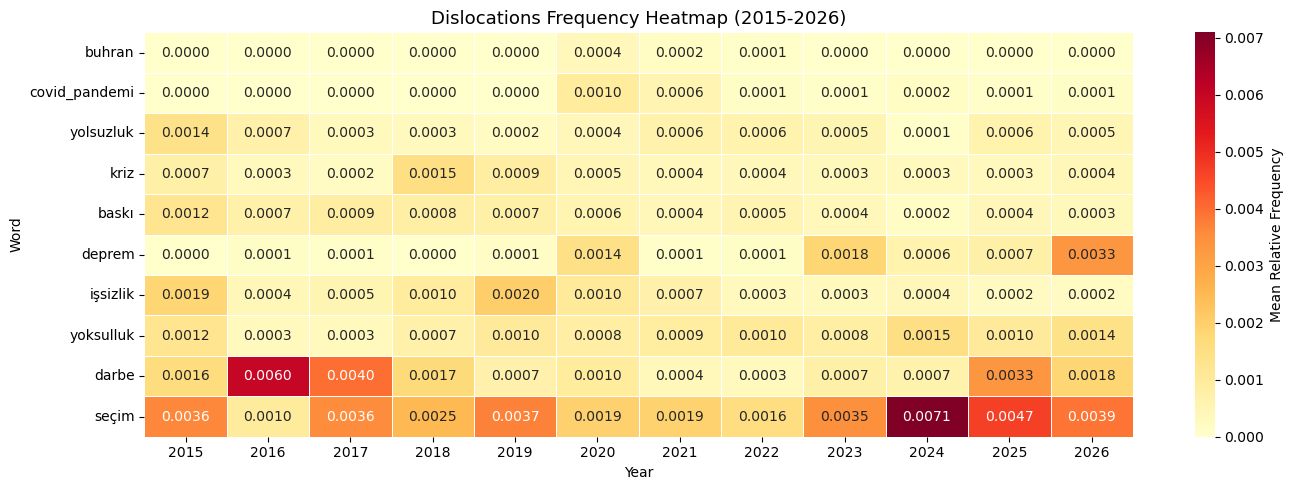

In [66]:
# theory-driven DISLOCATIONS candidates
DISLOCATIONS = ["deprem", "yolsuzluk", "işsizlik", "yoksulluk", "seçim", "darbe", "baskı", "kriz", "covid_pandemi", "buhran"]

pivot = word_freq_per_year(df, DISLOCATIONS)
pivot_sorted = pivot.loc[pivot.mean(axis=1).sort_values(ascending=True).index]

fig, ax = plt.subplots(figsize=(14, 5))

sns.heatmap(
    pivot_sorted,
    ax=ax,
    cmap="YlOrRd",        # light = rare, dark = frequent
    linewidths=0.4,
    annot=True,            # shows values in cells -- turn off if too crowded
    fmt=".4f",
    cbar_kws={"label": "Mean Relative Frequency"}
)

ax.set_title("Dislocations Frequency Heatmap (2015-2026)", fontsize=13)
ax.set_xlabel("Year")
ax.set_ylabel("Word")

plt.tight_layout()
plt.savefig("dislocations_heatmap.png", dpi=300)
plt.show()

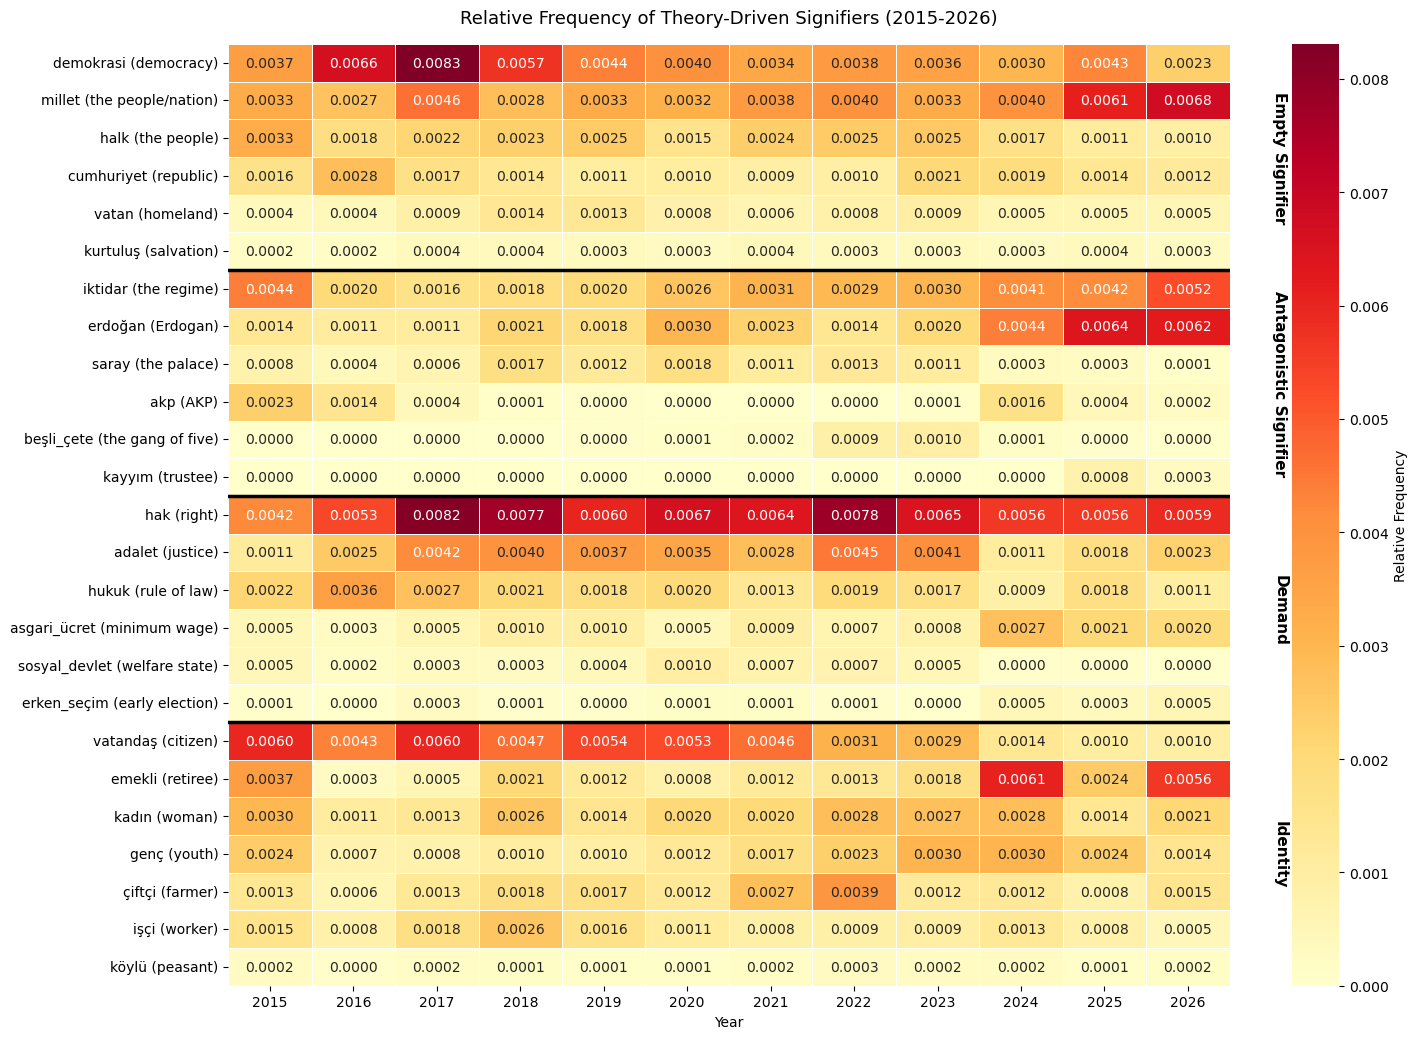

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle

# ============================================================
# AYARLAR: kelime, gloss, kategori
# ============================================================

CATEGORIES = {
    "Empty Signifier": {
        "millet":      "the people/nation",
        "halk":        "the people",
        "demokrasi":   "democracy",
        "cumhuriyet":  "republic",
        "vatan":       "homeland",
        "kurtuluş":    "salvation",
    },
    "Antagonistic Signifier": {
        "erdoğan":     "Erdogan",
        "iktidar":     "the regime",
        "saray":       "the palace",
        "akp":         "AKP",
        "beşli_çete":  "the gang of five",
        "kayyım":      "trustee",
    },
    "Demand": {
        "adalet":         "justice",
        "hak":            "right",
        "hukuk":          "rule of law",
        "asgari_ücret":   "minimum wage",
        "erken_seçim":    "early election",
        "sosyal_devlet":  "welfare state",
    },
    "Identity": {
        "emekli":     "retiree",
        "işçi":       "worker",
        "genç":       "youth",
        "kadın":      "woman",
        "çiftçi":     "farmer",
        "vatandaş":   "citizen",
        "köylü":     "peasant",
    },
}

CORPUS_PATH = "/Users/erenisikavci/Desktop/Thesis_Data/Data/corpus_main_phrases.csv"
TEXT_COL = "text_phrases"
OUTPUT_PATH = "combined_heatmap.png"

# ============================================================
# Yıllık relative frequency
# ============================================================

df = pd.read_csv(CORPUS_PATH)
df["year"] = pd.to_datetime(df["date"], dayfirst=True).dt.year

yearly_docs = df.groupby("year")[TEXT_COL].apply(lambda x: " ".join(x.dropna()))

def rel_freq_per_year(words):
    rows = []
    for year, doc in yearly_docs.items():
        tokens = doc.split()
        total = len(tokens)
        for w in words:
            rows.append({
                "word": w,
                "year": year,
                "rel_freq": tokens.count(w) / total if total > 0 else 0,
            })
    return pd.DataFrame(rows).pivot(index="word", columns="year", values="rel_freq")

# ============================================================
# Tüm kategorileri tek matrise yığ
# ============================================================

blocks = []
row_labels = []
category_boundaries = []  # (category_name, start_idx, end_idx)

current_idx = 0
for cat_name, word_gloss in CATEGORIES.items():
    words = list(word_gloss.keys())
    pivot = rel_freq_per_year(words)
    
    # Kategori içinde ortalama frekansa göre sırala (azalan)
    pivot = pivot.loc[pivot.mean(axis=1).sort_values(ascending=False).index]
    
    # Y-label: "kelime (gloss)"
    labels = [f"{w} ({word_gloss[w]})" for w in pivot.index]
    
    blocks.append(pivot)
    row_labels.extend(labels)
    
    start = current_idx
    end = current_idx + len(pivot)
    category_boundaries.append((cat_name, start, end))
    current_idx = end

full_matrix = pd.concat(blocks)
full_matrix.index = row_labels

# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(figsize=(15, len(full_matrix) * 0.42))

sns.heatmap(
    full_matrix,
    ax=ax,
    cmap="YlOrRd",
    linewidths=0.4,
    annot=True,
    fmt=".4f",
    cbar_kws={"label": "Relative Frequency"},
)

# Kategori ayırıcı çizgileri
for cat_name, start, end in category_boundaries[1:]:
    ax.axhline(start, color="black", linewidth=2.5)

# Kategori etiketleri sağ tarafta
for cat_name, start, end in category_boundaries:
    mid = (start + end) / 2
    ax.text(
        full_matrix.shape[1] + 0.6, mid,
        cat_name,
        rotation=270, va="center", ha="center",
        fontsize=11, fontweight="bold",
    )

ax.set_title("Relative Frequency of Theory-Driven Signifiers (2015-2026)",
             fontsize=13, pad=15)
ax.set_xlabel("Year")
ax.set_ylabel("")

plt.tight_layout()
plt.savefig(OUTPUT_PATH, dpi=300, bbox_inches="tight")
plt.show()

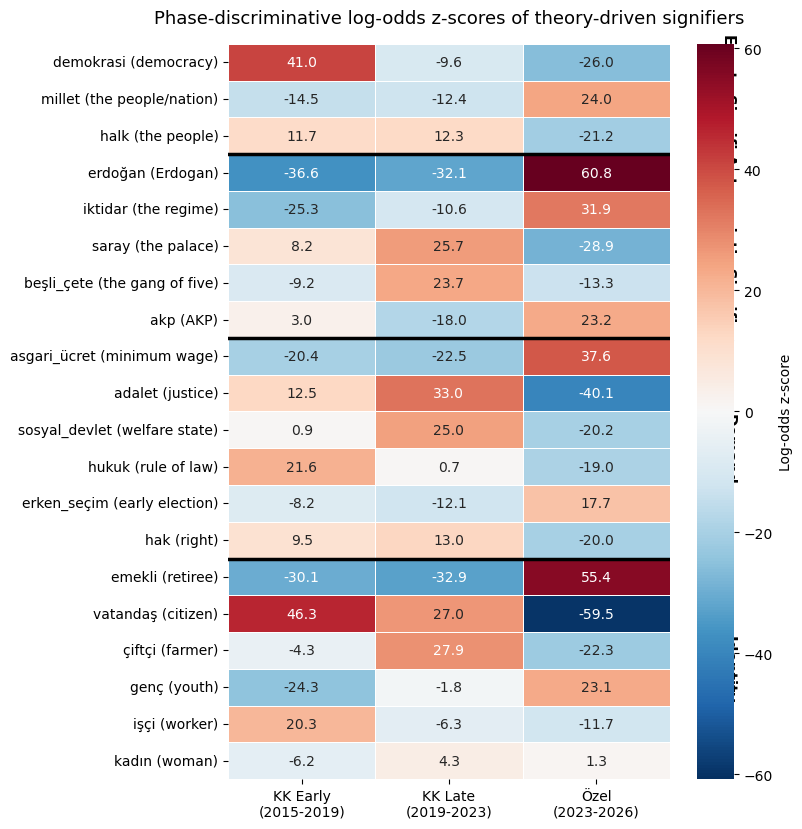

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer

# ============================================================
# AYARLAR: kelime, gloss, kategori (relfreq heatmap'iyle aynı)
# ============================================================

CATEGORIES = {
    "Empty Signifier": {
        "millet":      "the people/nation",
        "halk":        "the people",
        "demokrasi":   "democracy",
    },
    "Antagonistic Signifier": {
        "erdoğan":     "Erdogan",
        "iktidar":     "the regime",
        "saray":       "the palace",
        "akp":         "AKP",
        "beşli_çete":  "the gang of five",
    },
    "Demand": {
        "adalet":         "justice",
        "hak":            "right",
        "hukuk":          "rule of law",
        "asgari_ücret":   "minimum wage",
        "erken_seçim":    "early election",
        "sosyal_devlet":  "welfare state",
    },
}

CORPUS_PATH = "/Users/erenisikavci/Desktop/Thesis_Data/Data/corpus_main_phrases.csv"
TEXT_COL = "text_phrases"
OUTPUT_PATH = "logodds_combined_heatmap.png"
PHASE_LABELS = {
    "kk_early": "KK Early\n(2015-2019)",
    "kk_late":  "KK Late\n(2019-2023)",
    "ozel":     "Özel\n(2023-2026)",
}

# ============================================================
# Faz ataması
# ============================================================

df = pd.read_csv(CORPUS_PATH)
df["date"] = pd.to_datetime(df["date"], dayfirst=True)

ozel_start = pd.Timestamp("2023-11-04")
local_election_2019 = pd.Timestamp("2019-03-31")

def assign_phase(row):
    if row["speaker"] == "ozel" or row["date"] >= ozel_start:
        return "ozel"
    elif row["date"] <= local_election_2019:
        return "kk_early"
    else:
        return "kk_late"

df["phase"] = df.apply(assign_phase, axis=1)
phase_order = ["kk_early", "kk_late", "ozel"]

# ============================================================
# Count matrix (sigdict kelimelerini de yakalamak için min_df düşük)
# ============================================================

# Hangi kelimeleri arıyoruz, hepsi tek liste
all_terms = []
for cat in CATEGORIES.values():
    all_terms.extend(cat.keys())

count_vec = CountVectorizer(
    token_pattern=r"(?u)\b\w+\b",
    vocabulary=all_terms,  # sadece bu kelimeler
)
count_matrix = count_vec.fit_transform(df[TEXT_COL].fillna(""))
vocab = count_vec.get_feature_names_out()

# Faz başına toplam count
phase_counts = {}
for phase in phase_order:
    indices = df[df["phase"] == phase].index.tolist()
    phase_counts[phase] = np.array(count_matrix[indices].sum(axis=0)).flatten()

# ============================================================
# Log-odds (Monroe et al. 2008)
# ============================================================

def log_odds_ratio(target_counts, reference_counts, alpha=0.01):
    n_target = target_counts.sum()
    n_ref = reference_counts.sum()
    p_target = (target_counts + alpha) / (n_target + alpha * len(target_counts))
    p_ref = (reference_counts + alpha) / (n_ref + alpha * len(reference_counts))
    log_odds_target = np.log(p_target / (1 - p_target))
    log_odds_ref = np.log(p_ref / (1 - p_ref))
    delta = log_odds_target - log_odds_ref
    variance = (1 / (target_counts + alpha)) + (1 / (reference_counts + alpha))
    return delta / np.sqrt(variance)

# Her faz için z-score'lar
z_matrix = pd.DataFrame(index=vocab, columns=phase_order, dtype=float)
for target_phase in phase_order:
    other_phases = [p for p in phase_order if p != target_phase]
    target = phase_counts[target_phase]
    reference = sum(phase_counts[p] for p in other_phases)
    z = log_odds_ratio(target, reference)
    z_matrix[target_phase] = z

# ============================================================
# Kategori bazında yığ
# ============================================================

blocks = []
row_labels = []
category_boundaries = []

current_idx = 0
for cat_name, word_gloss in CATEGORIES.items():
    words = list(word_gloss.keys())
    sub = z_matrix.loc[words].copy()
    
    # Kategori içinde maksimum z-score'a göre azalan sıra
    sub = sub.loc[sub.max(axis=1).sort_values(ascending=False).index]
    
    labels = [f"{w} ({word_gloss[w]})" for w in sub.index]
    
    blocks.append(sub)
    row_labels.extend(labels)
    
    start = current_idx
    end = current_idx + len(sub)
    category_boundaries.append((cat_name, start, end))
    current_idx = end

full_matrix = pd.concat(blocks)
full_matrix.index = row_labels
full_matrix.columns = [PHASE_LABELS[p] for p in phase_order]

# ============================================================
# Plot
# ============================================================

# Renk skalası simetrik (sıfır ortada)
abs_max = full_matrix.abs().values.max()

fig, ax = plt.subplots(figsize=(8, len(full_matrix) * 0.42))

sns.heatmap(
    full_matrix,
    ax=ax,
    cmap="RdBu_r",       # diverging: mavi = az, kırmızı = çok ayırt edici
    center=0,
    vmin=-abs_max,
    vmax=abs_max,
    linewidths=0.4,
    annot=True,
    fmt=".1f",
    cbar_kws={"label": "Log-odds z-score"},
)

# Kategori ayırıcı çizgileri
for cat_name, start, end in category_boundaries[1:]:
    ax.axhline(start, color="black", linewidth=2.5)

# Kategori etiketleri sağda
for cat_name, start, end in category_boundaries:
    mid = (start + end) / 2
    ax.text(
        full_matrix.shape[1] + 0.4, mid,
        cat_name,
        rotation=270, va="center", ha="center",
        fontsize=11, fontweight="bold",
    )

ax.set_title("Phase-discriminative log-odds z-scores of theory-driven signifiers",
             fontsize=13, pad=15)
ax.set_xlabel("")
ax.set_ylabel("")
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig(OUTPUT_PATH, dpi=300, bbox_inches="tight")
plt.show()